# Overall results

/tmp/ipykernel_1393473/3534972990.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_last = df.groupby(["Benchmark", "Baseline"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)


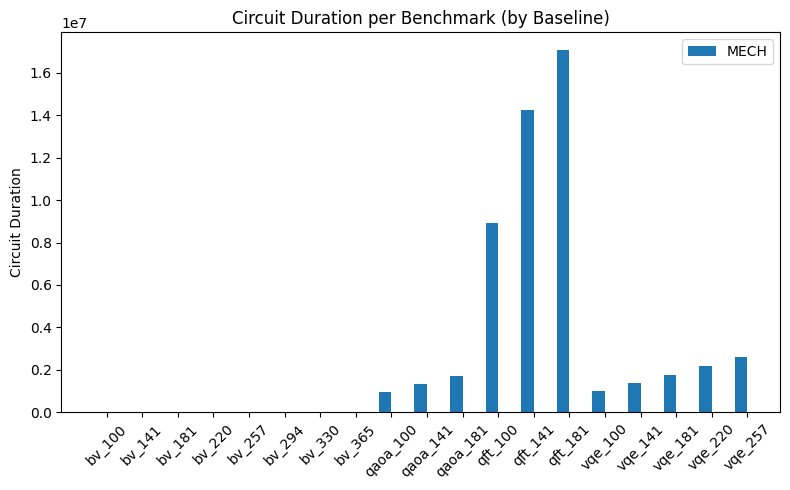

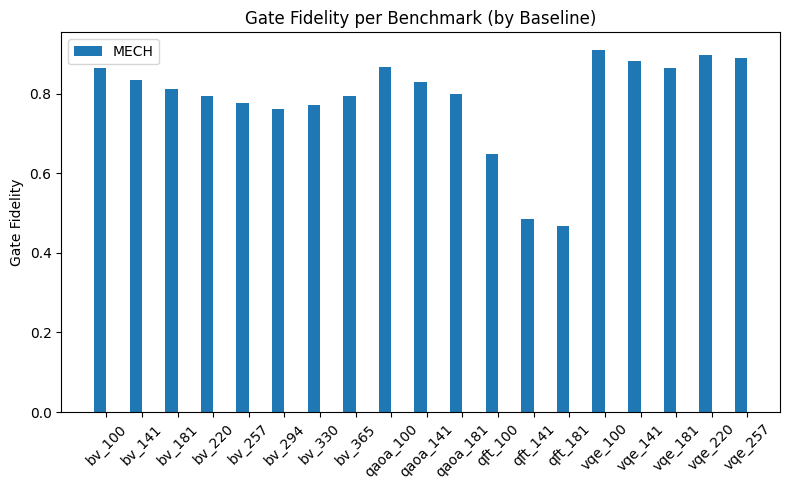

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

exp_dir = "./result/routing_scalability/benchmark"
output_path = os.path.join(exp_dir, "output.csv")
df = pd.read_csv(os.path.join(exp_dir, "output.csv"))
df["Benchmark"] = df["Algorithm"] + '_' + df["#DataQubit"].astype(str)
df_last = df.groupby(["Benchmark", "Baseline"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)

df_last["#DataQubit"] = df_last["#DataQubit"].astype(int)
df_last["Algorithm"] = df_last["Algorithm"].astype(str)
df_last_sorted = df_last.sort_values(by=["Algorithm", "#DataQubit"])
benchmarks = df_last_sorted[["Benchmark"]].drop_duplicates()["Benchmark"].tolist()
baselines = sorted(df_last["Baseline"].unique())
legend_dict = {"mech": "MECH", "qunoc": "Sensate"}

duration_data = {b: [] for b in baselines}
fidelity_data = {b: [] for b in baselines}

for bm in benchmarks:
    for bl in baselines:
        row = df_last[(df_last["Benchmark"] == bm) & (df_last["Baseline"] == bl)]
        if not row.empty:
            duration_data[bl].append(row["CircuitDuration"].values[0])
            fidelity_data[bl].append(row["GateFidelity"].values[0])
        else:
            duration_data[bl].append(np.nan)
            fidelity_data[bl].append(np.nan)

x = np.arange(len(benchmarks))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
for i, bl in enumerate(baselines):
    ax.bar(x + i * width, duration_data[bl], width, label=legend_dict[bl])
ax.set_ylabel("Circuit Duration")
ax.set_title("Circuit Duration per Benchmark (by Baseline)")
ax.set_xticks(x + width / 2)
ax.set_xticklabels(benchmarks, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_duration.svg"))
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_duration.pdf"))
plt.show()
plt.close()

fig, ax = plt.subplots(figsize=(8, 5))
for i, bl in enumerate(baselines):
    ax.bar(x + i * width, fidelity_data[bl], width, label=legend_dict[bl])
ax.set_ylabel("Gate Fidelity")
ax.set_title("Gate Fidelity per Benchmark (by Baseline)")
ax.set_xticks(x + width / 2)
ax.set_xticklabels(benchmarks, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_fidelity.svg"))
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_fidelity.pdf"))
plt.show()
plt.close()

# Layout Evaluation

## Scalability on package size

/tmp/ipykernel_1393473/1937871222.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby(["PackageSize", "DesignStrategy"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)


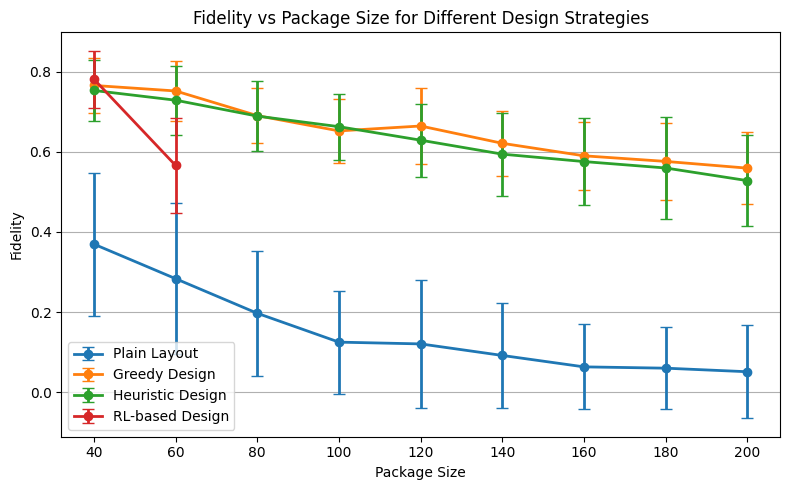

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

exp_dir = "./result/layout_scalability/package_size"
output_path = os.path.join(exp_dir, "output.csv")
df = pd.read_csv(os.path.join(exp_dir, "output.csv"))
df = df.groupby(["PackageSize", "DesignStrategy"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)
plt.figure(figsize=(8, 5))
design_strategies = df["DesignStrategy"].unique()
legend_dict = {"baseline": "Plain Layout", "heuristic": "Heuristic Design", "greedy": "Greedy Design", "rl": "RL-based Design"}

for design_strategy in design_strategies:
    subset = df[df["DesignStrategy"] == design_strategy]
    x = subset['PackageSize']
    y = subset['Fidelity']
    yerr = subset['FideStd']
    plt.errorbar(
        x, y, yerr=yerr,
        label=legend_dict[design_strategy],
        marker='o',
        capsize=4,
        linestyle='-',
        linewidth=2
    )

plt.xlabel("Package Size")
plt.ylabel("Fidelity")
plt.title("Fidelity vs Package Size for Different Design Strategies")
plt.grid(True, axis='y')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "layout_scalability_package_size.svg"))
plt.savefig(os.path.join("./result/plot", "layout_scalability_package_size.pdf"))
plt.show()
plt.close()

# Routing Evaluation